# H4: why Dec does worse than RA (internal)

Hypothesis (from H2): after DCR, epochs scatter more ALONG the parallactic direction than across it; at CTIO the
parallactic direction is mostly north-south, so the excess lands in Dec. Tests on clean Gaia stars, sigma < 10 mas
epochs, fully corrected offsets, slice 000 (Dec -90 to +35):
1. geometry: share of the parallactic direction along Dec, |cos PA|;
2. along / across scatter vs tan z -- an excess growing with airmass means refraction-related;
3. RA / Dec scatter vs the field's Dec;
4. size of the excess, and the Dec/RA ratio it predicts vs the pulls.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import dcr_fit, plot_style as ps
ps.apply()
OUT = 'plots/'
S = dcr_fit.load_stage_sample(['000'])
m0 = S['clean'] & np.isfinite(S['c_rel'])
rs = lambda v: 1.4826 * np.median(np.abs(v - np.median(v)))
ST = 'lm'   # fully corrected
par, perp, pa = S[f'par_{ST}'], S[f'perp_{ST}'], S['pa']
ddec = -(par * np.cos(pa) + perp * np.sin(pa))     # mas; pixel -> sky as in the pipeline (dRA = +0.262 dy, dDec = -0.262 dx)
dra = -par * np.sin(pa) + perp * np.cos(pa)
print(f"{m0.sum():,} epochs; per-axis robust scatter: RA {rs(dra[m0]):.2f}, Dec {rs(ddec[m0]):.2f} mas; "
      f"along {rs(par[m0]):.2f}, across {rs(perp[m0]):.2f} mas")

3,315,075 epochs; per-axis robust scatter: RA 11.19, Dec 13.47 mas; along 13.17, across 11.68 mas


median |cos PA| = 0.79; fraction with |cos PA| > 0.9: 0.36


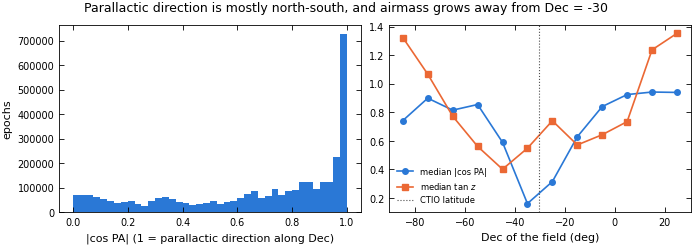

In [2]:
# 1. Geometry: how much of the parallactic direction is along Dec, overall and vs the field's Dec
fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 2.5), constrained_layout=True)
axes[0].hist(np.abs(np.cos(pa[m0])), bins=40, range=(0, 1), color=ps.SERIES[0])
axes[0].set_xlabel('|cos PA| (1 = parallactic direction along Dec)'); axes[0].set_ylabel('epochs')
db = np.arange(-90, 41, 10); dc = 0.5 * (db[1:] + db[:-1])
med = [np.median(np.abs(np.cos(pa[m0 & (S['dec'] > a) & (S['dec'] <= b)]))) if (m0 & (S['dec'] > a) & (S['dec'] <= b)).sum() > 1000 else np.nan for a, b in zip(db, db[1:])]
tz = [np.median(S['tanz'][m0 & (S['dec'] > a) & (S['dec'] <= b)]) if (m0 & (S['dec'] > a) & (S['dec'] <= b)).sum() > 1000 else np.nan for a, b in zip(db, db[1:])]
axes[1].plot(dc, med, marker=ps.MARKERS[0], color=ps.SERIES[0], label='median |cos PA|')
axes[1].plot(dc, tz, marker=ps.MARKERS[1], color=ps.SERIES[1], label='median tan $z$')
axes[1].axvline(-30.17, color='0.3', ls=':', lw=0.8, label='CTIO latitude')
axes[1].set_xlabel('Dec of the field (deg)'); axes[1].legend(fontsize=6)
fig.suptitle('Parallactic direction is mostly north-south, and airmass grows away from Dec = -30')
plt.savefig(OUT + 'h4_geometry.pdf')
print(f"median |cos PA| = {np.median(np.abs(np.cos(pa[m0]))):.2f}; fraction with |cos PA| > 0.9: {np.mean(np.abs(np.cos(pa[m0])) > 0.9):.2f}")

g: excess along (mas) by tan z bin: [ 8.5  6.3  6.8  9.8  7.6  6.9  8.8 12.9]; fit excess = 11.2 mas x tan z
r: excess along (mas) by tan z bin: [6.5 6.5 4.4 4.7 5.7 5.2 5.7 9.4]; fit excess = 7.8 mas x tan z
i: excess along (mas) by tan z bin: [0.  3.5 5.  5.6 5.5 5.2 6.1 6. ]; fit excess = 6.8 mas x tan z
z: excess along (mas) by tan z bin: [1.9 3.2 3.2 3.1 3.8 4.8 5.4 9.8]; fit excess = 6.9 mas x tan z


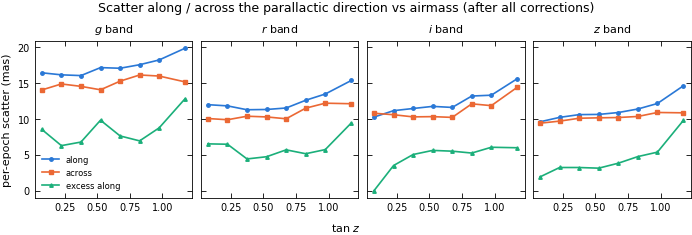

In [3]:
# 2. Along vs across scatter vs tan z, per band; excess = sqrt(along^2 - across^2)
tb = np.array([0, 0.15, 0.3, 0.45, 0.6, 0.75, 0.9, 1.05, 1.3]); tc = 0.5 * (tb[1:] + tb[:-1])
fig, axes = plt.subplots(1, 4, figsize=(ps.PAGE, 2.4), sharex=True, sharey=True, constrained_layout=True)
EXC = {}
for ax, b in zip(axes, 'griz'):
    al, ac = [], []
    for a, c in zip(tb, tb[1:]):
        m = m0 & (S['band'] == b) & (S['tanz'] > a) & (S['tanz'] <= c)
        al.append(rs(par[m]) if m.sum() > 500 else np.nan); ac.append(rs(perp[m]) if m.sum() > 500 else np.nan)
    al, ac = np.array(al), np.array(ac)
    exc = np.sqrt(np.clip(al**2 - ac**2, 0, None))
    EXC[b] = exc
    for k, (y, label) in enumerate([(al, 'along'), (ac, 'across'), (exc, 'excess along')]):
        ax.plot(tc, y, marker=ps.MARKERS[k], ms=2.5, color=ps.SERIES[k], label=label)
    ax.set_title(f'${b}$ band')
axes[0].set_ylabel('per-epoch scatter (mas)'); axes[0].legend(fontsize=6)
fig.supxlabel('tan $z$', fontsize=8)
fig.suptitle('Scatter along / across the parallactic direction vs airmass (after all corrections)')
plt.savefig(OUT + 'h4_along_across_vs_airmass.pdf')
for b in 'griz':
    ok = np.isfinite(EXC[b])
    k = np.sum(EXC[b][ok] * tc[ok]) / np.sum(tc[ok]**2)   # excess ~ k tan z
    print(f'{b}: excess along (mas) by tan z bin: {np.round(EXC[b], 1)}; fit excess = {k:.1f} mas x tan z')

Dec/RA per-epoch scatter ratio: 1.20 (clean-star PM pull ratio Dec/RA ~ 1.30/1.08 = 1.20)


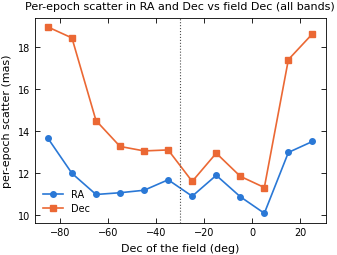

In [4]:
# 3. RA and Dec scatter vs the field's Dec
fig, ax = plt.subplots(figsize=(ps.COLUMN, 2.6), constrained_layout=True)
for k, (v, label) in enumerate([(dra, 'RA'), (ddec, 'Dec')]):
    y = [rs(v[m0 & (S['dec'] > a) & (S['dec'] <= b)]) if (m0 & (S['dec'] > a) & (S['dec'] <= b)).sum() > 1000 else np.nan for a, b in zip(db, db[1:])]
    ax.plot(dc, y, marker=ps.MARKERS[k], color=ps.SERIES[k], label=label)
ax.axvline(-30.17, color='0.3', ls=':', lw=0.8)
ax.set_xlabel('Dec of the field (deg)'); ax.set_ylabel('per-epoch scatter (mas)'); ax.legend()
ax.set_title('Per-epoch scatter in RA and Dec vs field Dec (all bands)')
plt.savefig(OUT + 'h4_ra_dec_vs_dec.pdf')
r_epoch = rs(ddec[m0]) / rs(dra[m0])
print(f'Dec/RA per-epoch scatter ratio: {r_epoch:.2f} (clean-star PM pull ratio Dec/RA ~ 1.30/1.08 = {1.30/1.08:.2f})')